## 비지도 학습
정답(`y`) 없이 입력 데이터(피처, `X`)의 구조와 패턴을 학습하는 방법.

|구분|지도학습|비지도학습|
|---|---|---|
|**데이터**|입력 + 정답 (`fit(X, y)`)|ONLY 입력(`fit(X)`)|
|**목표**|정답 예측/분류|숨은 패턴/구조 발견|
|**평가**|정답과 비교 (정확도, f1 등)|정량 지표(실루엣 등) + 도메인 해석|

### 대표적인 유형
- **군집화 (Clustering)**: 비슷한 특성의 데이터끼리 그룹화
- **차원 축소 (Dimensionality Reduction)**: 많은 피처를 적은 수의 핵심 축으로 압축
    -> 다중공산성 완화 및 시각화
- **이상 탐지 (Anomaly Detection)**: 정상 범위에서 벗어난 패턴 감지, 이상 거래 및 급변 탐지

> 거리, 분산 기반 알고리즘이 많아 **스케일링이 필수**이며, 군집의 의미는 최종적으로 **도메인 지식으로 검증**해야 한다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _style import setup
from _ml import load_merged, SEED

setup()
pd.set_option("display.width", 130)

print("준비 완료!")

준비 완료!


In [2]:
# 120개 종목을 수익률 패턴으로 군집화하고, 실제 섹터와 비교

df = load_merged()

# 일간 수익률 피처 추가
df["ret"] = df.groupby("code")["close"].pct_change()

# 데이터를 (종목 * 날짜) 행렬로 만들기
# 행 = 날짜, 열 = 종목, 값 = 수익률
# df.pivot(index=행, colums=열, values=값)
pivot = df.pivot_table(index="date", columns="code", values="ret")

# 종목별 섹터
# df[["code", "name"]].drop_duplicates(): 종목, 섹터 기준으로 중복 제거
# .set_index("code")["sectorName"]: 코드를 인덱스로 하여 섹터 이름 열만
#                인덱싱하여, '종목코드: 섹터이름' 형태의 Series로 만들기
sector = df[["code", "sectorName"]].drop_duplicates().set_index("code")["sectorName"]
# sector[pivot.columns]: 섹터 Series 값들을 피벗 df의 컬럼 순서대로 가져오기
# .values: 가져온 값들을 ndarray 형태로 변환.
true_labels = sector[pivot.columns].values

print(f"수익률 행렬: {pivot.shape} (날짜 x 종목)")
print(f"군집화 입력: {pivot.T.shape} (종목 x 날짜)")
print()
print("종목을 묶을 것이므로 '종목이 행'이 되도록 전치(.T)한다")
print(f"각 종목이 {pivot.shape[0]}개의 값으로 표현된다. (날짜별 수익률)")
print()
print(f"섹터 {len(set(true_labels))}종류, 종목 {len(true_labels)}개")
print(pd.DataFrame(true_labels).value_counts())

수익률 행렬: (749, 120) (날짜 x 종목)
군집화 입력: (120, 749) (종목 x 날짜)

종목을 묶을 것이므로 '종목이 행'이 되도록 전치(.T)한다
각 종목이 749개의 값으로 표현된다. (날짜별 수익률)

섹터 10종류, 종목 120개
0    
금융       18
전기전자     16
IT서비스    14
유통       12
화학       12
바이오      12
운수장비     12
건설       10
에너지       8
식품        6
Name: count, dtype: int64


---
### K_Means 군집화
k개의 평균을 찾는 알고리즘.

1. k개의 중심점 선정
2. 각 데이터를 가장 가까운 중심점에 배정
3. 각 그룹의 평균으로 중심점 이동
4. 중심점이 움직이지 않을 때까지 2, 3 과정 반복

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (adjusted_rand_score, 
                             silhouette_score, 
                             davies_bouldin_score)

def clustering(matrix, k=10, scale=True):
    """군집화하여 결과를 반환"""
    # 전달받은 행렬을 전치(.T)
    M = matrix.T.values

    if scale:
        # fit_transform(M): fit, transform을 한꺼번에 수행
        # fit: 데이터의 평균과 표준편차 계산
        # transform: 실제로 그 값들로 데이터 변환
        M = StandardScaler().fit_transform(M)

    # km = KMeans(n_clusters=k)
    # 시도할 때마다 다른 결과가 출력됨. => random_seed 옵션까지 설정
    km = KMeans(
        n_clusters=k,
        random_state=SEED,
        # n번 시도하여 가장 좋은 결과를 고르는 옵션
        n_init=10,
    )

    # 학습된 중심을 기준으로 각 종목이 몇 번 군집(0~9번)에 속하는지 예측
    # => 결과 라벨을 1차원 배열로 반환한다.
    pred = km.fit_predict(M)

    # 예측결과, 입력 데이터(X), 모델 반환
    return pred, M, km

preds, M_scaled, km = clustering(pivot, k=10, scale=True)

print("군집별 종목 수: ")
print(pd.Series(preds).value_counts().sort_index().to_string())

군집별 종목 수: 
0     5
1    18
2    25
3    14
4     2
5    15
6    13
7     7
8    12
9     9


#### 재현성
**`random_state`, `n_init`을 둘 다 지정해야 실행할 때마다 동일한 결과**를 확인할 수 있다.
설정하지 않으면 중심점을 무작위로 찍고 시작하므로 실행마다 다른 군집이 나올 수 있다.

- random_state=42: 랜덤 시드를 동일하게 주어 항상 같은 곳을 중심점으로 찍게 한다.
- n_init=10: 여러 번 시도해서 가장 좋은 결과를 고른다.
---

## 스케일링 처리 유/무 비교

In [4]:
# 스케일링 처리 X
lab_raw, M_raw, _ = clustering(pivot, k=10, scale=False)
# 스케일링 처리 O
lab_scaled, M_scaled, _ = clustering(pivot, k=10, scale=True)

vol = pivot.std()

rows = []

for name, lab in [("스케일링 X", lab_raw), ("스케일링 O", lab_scaled)]:
    # 각 군집의 평균 변동성을 구하여 가장 높은 군집과 가장 낮은 군집 간 차이
    # groupby(lab): 각각의 군집으로 그룹화
    vol_by_cluster = pd.Series(vol.values).groupby(lab).mean()

    rows.append({
        "방식": name,
        "섹터와의 일치 여부(ARI)": adjusted_rand_score(true_labels, lab),
        "군집 간 변동성 차이": vol_by_cluster.max() - vol_by_cluster.min()
    })
    # ARI: 두 그룹이 얼마나 일치하는가? 얼마나 비슷하게 잘 묶였는가?를 나타내는 지표
    # 1.0:  완전 일치, 0.0: 무작위와 같음
    # * 정답이 없는 비지도학습이므로 원래는 이 방식을 적용하기 어려우나,
    #   참고할 수 있는 데이터가 있으므로 비교가 가능하다.

print(pd.DataFrame(rows).round(4).to_string(index=False))

    방식  섹터와의 일치 여부(ARI)  군집 간 변동성 차이
스케일링 X           0.0333       0.0035
스케일링 O           0.5265       0.0053


**스케일링이 없는 경우(X)는 섹터 구분이 전혀 안 됨! (ARI 0.0333)**
K-Means는 거리로 판단하므로, 모든 종목에 똑같이 더해지는 시장 흐름은 종목 간 거리에서 상쇄될 것이다. 대신, 변동이 큰 날의 값이 거리를 좌우하므로 섹터의 차이가 묻히는 것으로 보이게 된다. 하니잠 스케일링(`StandardSclaer`)을 적용하면 ARI가 약 0.5265까지 올라간다.

In [5]:
cross_table = pd.crosstab(pd.Series(lab_scaled, name="군집"),
                          pd.Series(true_labels, name="섹터"))
most = cross_table.max(axis=1).sum()

print(cross_table.to_string())
print()
print(f"군집 순도: {most / cross_table.values.sum():.2f}")

섹터  IT서비스  건설  금융  바이오  식품  에너지  운수장비  유통  전기전자  화학
군집                                                 
0       0   0   0    2   0    0     2   0     0   1
1       0   1  16    0   1    0     0   0     0   0
2      14   0   0    1   0    0     5   1     3   1
3       0   9   1    0   0    0     2   1     0   1
4       0   0   0    0   1    1     0   0     0   0
5       0   0   0    2   0    0     1   0    12   0
6       0   0   0    0   1    0     1  10     1   0
7       0   0   0    7   0    0     0   0     0   0
8       0   0   1    0   3    7     1   0     0   0
9       0   0   0    0   0    0     0   0     0   9

군집 순도: 0.72


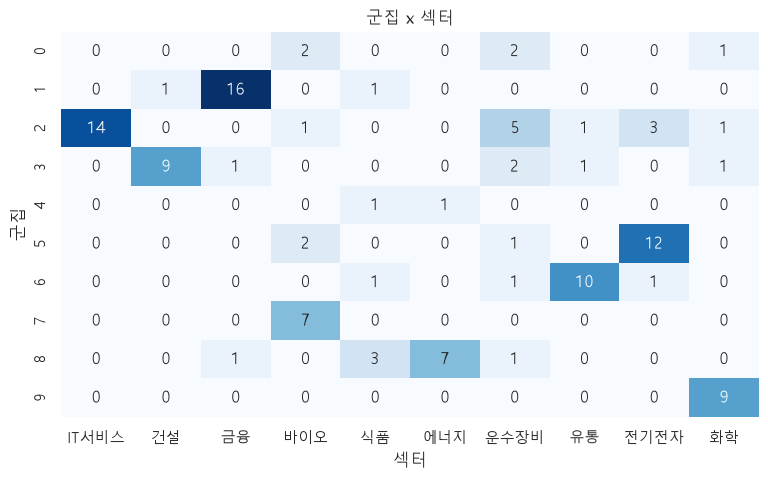

In [6]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(9, 5))

sns.heatmap(cross_table, annot=True, fmt="d", 
            cmap="Blues", cbar=False, ax=ax)
ax.set_title("군집 x 섹터")

plt.show()

#### 군집 결과 (k=10, 스케일링 적용)
- 순도 0.72: 각 군집에서 가장 많은 섹터의 종목 수를 모두 더해 전체 종목 수(120)로 나눈 값. 1.0이면 군집과 섹터가 완전히 일치함을 의미한다.
- 잘 묶어진 섹터: IT 서비스(14/14), 금융(16/18), 건설(9/10), 화학(9/12), 전기전자(12/16)
- 섞인 것: 운수장비(12)는 어느 군집도 주도하지 못하고 흩어져 있다(최대 5). 군집 8번은 에너지(7), 식품(3)가 섞여 있다. 군집 0번, 4번은 작게 섞여 있는 군집이다.
- 순도는 군집 수가 많을수록 높아지기 쉬운 지표(k=종목수 -> 1.0)이므로 ARI(0.5265)를 함께 활용하여 분석해야 한다.
- 같은 섹터 종목이 비슷하게 움직인다는 가정은 대체로 맞다. 다만, 운수장비처럼 수익률 패턴이 섹터 안에서 제각각인 경우에는 수익률만으로 구분이 어렵다.

---

### k값을 정하는 방법

|방법|보는 관점|방향|
|---|---|---|
|엘보|K를 늘릴수록 오차가 줄어든다. 꺾이는 지점|-|
|실루엣 계수|군집 안은 뭉치고, 군집 간은 떨어졌는가?|높을수록 좋음|
|DBI|군집끼리 잘 분리되었는가?|낮을수록 좋음|

In [9]:
ks = range(2, 16)
rows = []

for k in ks:
    # k값을 변경하면서 KMeans 모델 생성 -> 군집화
    km_k = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(M_scaled)

    # labels_ 속성으로 학습한 모델의 labels 가져오기
    lab_k = km_k.labels_

    rows.append({
        "k": k,
        # inertia_ : 엘보 확인용(낮을수록 좋음)
        "관성": km_k.inertia_,
        # 군집 간 분리도와 군집 내부 응집도를 종합적으로 판단
        # 높을수록 좋음
        "실루엣": silhouette_score(M_scaled, lab_k),
        # 낮을수록 좋음
        "DBI": davies_bouldin_score(M_scaled, lab_k),
        "ARI(참고)": adjusted_rand_score(true_labels, lab_k)
    })

k_table = pd.DataFrame(rows)

print(k_table.round(4).to_string(index=False))

 k         관성    실루엣    DBI  ARI(참고)
 2 86829.6581 0.0249 5.3262   0.1593
 3 85487.7156 0.0163 5.0055   0.2217
 4 84580.5442 0.0139 5.1342   0.2523
 5 83066.5696 0.0134 4.7518   0.2501
 6 82233.8038 0.0084 4.6291   0.2950
 7 80815.0873 0.0141 4.5523   0.4656
 8 80265.0721 0.0089 4.4493   0.4634
 9 79205.4191 0.0027 3.7824   0.4252
10 77600.6181 0.0147 3.7209   0.5265
11 77306.6468 0.0075 3.7116   0.4172
12 76122.9891 0.0047 3.6581   0.4532
13 74993.5229 0.0154 3.3516   0.5808
14 74657.9752 0.0018 3.5112   0.3796
15 73741.1954 0.0054 3.0951   0.5034


C:\Users\user1\AppData\Local\Temp\ipykernel_22732\991495674.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[2].legend()


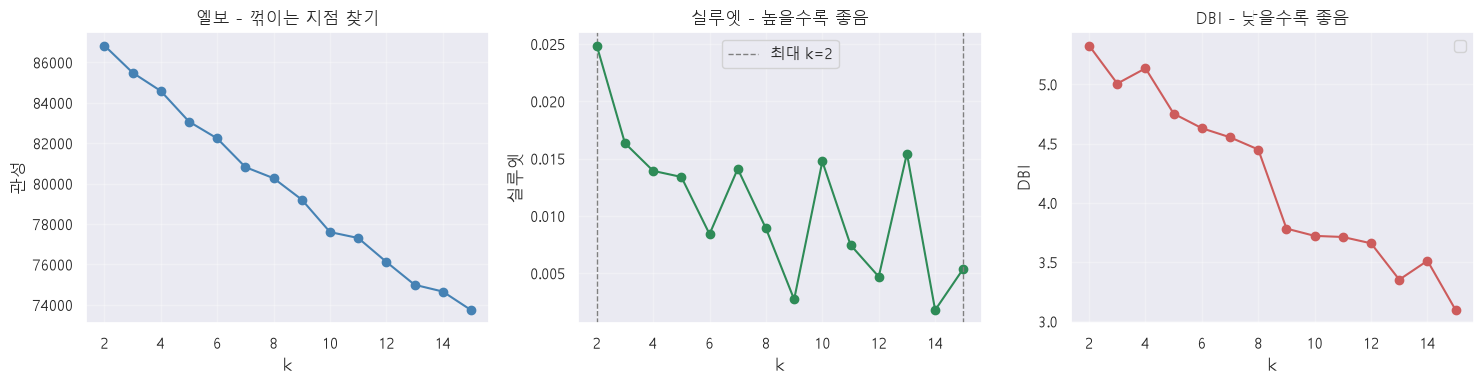

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. 엘보
axes[0].plot(k_table["k"], k_table["관성"], "o-", color="steelblue")
axes[0].set_xlabel("k")
axes[0].set_ylabel("관성")
axes[0].set_title("엘보 - 꺾이는 지점 찾기")
axes[0].grid(alpha=0.3)

# 2. 실루엣
best_sil = k_table.loc[k_table["실루엣"].idxmax(), "k"]

axes[1].axvline(best_sil, color="gray", ls="--", lw=1, label=f"최대 k={best_sil}")
axes[1].plot(k_table["k"], k_table["실루엣"], "o-", color="seagreen")
axes[1].set_xlabel("k")
axes[1].set_ylabel("실루엣")
axes[1].set_title("실루엣 - 높을수록 좋음")
axes[1].legend()
axes[1].grid(alpha=0.3)

# 3. DBI
axes[2].plot(k_table["k"], k_table["DBI"], "o-", color="indianred")
best_dbi = k_table.loc[k_table["DBI"].idxmin(), "k"]
axes[2].axvline(best_dbi, color="gray", ls="--", lw=1, label=f"최소 k={best_dbi}")
axes[2].set_xlabel("k")
axes[2].set_ylabel("DBI")
axes[2].set_title("DBI - 낮을수록 좋음")
axes[2].legend()
axes[2].grid(alpha=0.3)

fig.tight_layout()
plt.show()

**1. 엘보가 뚜렷하지 않다.**
> 관성 곡선이 완만하게 내려가기만 해서 어디가 팔꿈치 지점인지 알 수 없다. -> 일반적인 현상!

**2. 실루엣이 매우 낮다 (0.02 수준)**
> 군집이 뚜렷하게 나뉘지 않는다. -> 금융 수익률 데이터에서는 일반적!

**3. 모든 지표가 다른 K가 좋다고 나타난다.**
> 실루엣이 작은 k, DBI가 큰 k가 각각 있다. 이때 어느 하나를 기계적으로 믿어서는 안 된다.\
> 결국 도메인 지식이 필요한데, 이번 데이터에서는 섹터가 10개이므로 k=10